# Middle-layer loss and extra transfer checks (re-runs)

Follow-up to notebooks 01–03. Two questions from the group:

1. **Does the attack get stronger if the loss also looks at the middle layers of the encoder**, not only at its final output?
2. **How far does the perturbation transfer** beyond SmolVLM-500M / 2.2B?

Everything else is unchanged from notebook 01 (same data split, ε = 10/255, Adam lr 1/255, batch 8, 10 epochs, describe prompt, greedy decoding, MiniLM threshold 0.5). Every number is measured through the **real pipeline** (v saved in an 8-bit image, standard processor).

| | Notebook 01 | This notebook |
|---|---|---|
| Loss target | `last_hidden_state` only | any encoder state `h1`…`h12`, the output (`final`), or an average over several |
| Encoder forward | `VIS(pixel_values).last_hidden_state` | layer-by-layer loop that keeps every state (checked identical to the official forward) |
| Transfer targets | 500M, 2.2B | 500M, 2.2B, **original Google SigLIP-B/16-512** (zero-shot), **ResNet-50**, **ViT-B/16** |

**How to run.** `RERUN = False` (default) reloads the saved results from `uap_smolvlm/reruns/` and only draws tables and figures: no GPU needed, a few seconds. `RERUN = True` recomputes everything on a Colab GPU and saves to Drive (about 3–4 h on a T4; it was 2 h on an RTX 4050 with bfloat16 training).

The results were produced with the scripts in `smol_exp/reruns_code/` (run locally on an RTX 4050); this notebook contains the same code, and the saved results are in `uap_smolvlm/reruns/`.

## 1. Configuration

In [1]:
RERUN = False          # False: load saved results and plot. True: recompute everything (GPU, hours).

MODELS = {"256M": "HuggingFaceTB/SmolVLM-256M-Instruct",
          "500M": "HuggingFaceTB/SmolVLM-500M-Instruct",
          "2.2B": "HuggingFaceTB/SmolVLM-Instruct"}
IMG_SIZE, N_BUILD, N_EVAL = 512, 500, 500
NORM_XI, EPOCHS, BATCH, LR = 10/255, 10, 8, 1/255
PROMPT, MAX_NEW_TOKENS, CAPTION_SIM_CHANGED, SEED = "Describe this image in one sentence.", 40, 0.5, 0

# Which encoder states the loss looks at. h0 = after patch + position embedding, hk = output of layer k,
# final = post_layernorm(h12) = last_hidden_state (the target of notebook 01).
TARGETS = {"final": ["final"],
           **{f"h{k}": [f"h{k}"] for k in (2, 3, 4, 6, 8, 9, 10, 12)},
           "multi_mid": ["h3", "h6", "h9"],
           "multi":     ["h3", "h6", "h9", "final"],
           "multi_all": [f"h{k}" for k in range(1, 13)] + ["final"]}
LABEL = {"random": "random ±ε", "group_final": "group v (final, nb 01)", "final": "final (re-trained)",
         "multi_mid": "h3+h6+h9", "multi": "h3+h6+h9+final", "multi_all": "h1…h12+final",
         **{f"h{k}": f"layer {k}" for k in range(1, 13)}}
ORDER = ["random", "group_final", "final", "h2", "h3", "h4", "h6", "h8", "h9", "h10", "h12", "multi_mid", "multi", "multi_all"]

## 2. Setup

In [2]:
import os, json, math, time, glob, tarfile
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

IN_COLAB = "COLAB_GPU" in os.environ or os.path.exists("/content")
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
    RES = Path("/content/drive/MyDrive/uap_smolvlm/reruns")
    GROUP_V = Path("/content/drive/MyDrive/uap_smolvlm/uap_smolvlm256m_linf10.npy")
else:                                   # local clone of the repo: results live next to this notebook
    RES = Path("uap_smolvlm/reruns")
    GROUP_V = Path("uap_smolvlm/uap_smolvlm256m_linf10.npy")
RES.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RERUN:
    assert DEVICE == "cuda", "RERUN needs a GPU: Runtime -> Change runtime type -> T4 GPU"
    if IN_COLAB:
        os.system('pip -q install "transformers>=4.50" sentence-transformers sentencepiece')

def load(name):
    p = RES / name
    return json.load(open(p, encoding="utf-8")) if p.exists() else None

def save(name, obj):
    with open(RES / name, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=1, ensure_ascii=False, default=float)

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

pct = lambda x: f"{100 * x:.1f}%"
print("results folder:", RES.resolve(), "| RERUN =", RERUN, "| device:", DEVICE)

results folder: C:\Users\david\OneDrive\Desktop\EA\repo\smol_exp\uap_smolvlm\reruns | RERUN = False | device: cuda


## 3. Helpers (used only when `RERUN = True`)

The key piece is `encoder_states`: it runs the SigLIP encoder layer by layer and returns every intermediate state, so the loss can target any of them. Everything else is the code of notebooks 01–02.

In [3]:
def encoder_states(vis, pixel_values, upto=None):
    """{'h0'..'h12', 'final'}; stops after layer `upto` if given (cheaper for middle-layer targets)."""
    B, ps = pixel_values.shape[0], vis.config.patch_size
    mask = torch.ones(B, pixel_values.shape[2] // ps, pixel_values.shape[3] // ps, dtype=torch.bool, device=pixel_values.device)
    h = vis.embeddings(pixel_values=pixel_values, patch_attention_mask=mask)
    out = {"h0": h}
    for k, layer in enumerate(vis.encoder.layers[:upto or len(vis.encoder.layers)]):
        h = layer(h, None); out[f"h{k + 1}"] = h
    if upto is None:
        out["final"] = vis.post_layernorm(h)
    return out

norm = lambda x01: (x01 - 0.5) / 0.5                        # SmolVLM image_mean = image_std = 0.5
tok_cos = lambda a, b: F.cosine_similarity(a.float(), b.float(), dim=-1).mean(dim=1)
to01 = lambda u8: u8.to(DEVICE).float().div(255)

def random_v():
    torch.manual_seed(SEED)
    return NORM_XI * torch.sign(torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))

def load_v(name):
    if name == "random": return random_v()
    p = GROUP_V if name == "group_final" else RES / f"v_{name}.npy"
    return torch.from_numpy(np.load(p)).float().to(DEVICE)

def train_uap(vis, build_u8, target):
    keys = TARGETS[target]
    upto = None if "final" in keys else max(int(k[1:]) for k in keys)
    amp = torch.cuda.is_bf16_supported()                     # bfloat16 on Ampere+ GPUs, fp32 on a T4
    g = torch.Generator().manual_seed(SEED)
    v = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE, requires_grad=True)
    opt, hist, t0 = torch.optim.Adam([v], lr=LR), [], time.time()
    for ep in range(EPOCHS):
        losses = []
        for idx in torch.randperm(len(build_u8), generator=g).split(BATCH):
            x = to01(build_u8[idx])
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp):
                with torch.no_grad():
                    zc = encoder_states(vis, norm(x), upto)
                za = encoder_states(vis, norm((x + v).clamp(0, 1)), upto)
                loss = torch.stack([tok_cos(zc[k], za[k]).mean() for k in keys]).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): v.clamp_(-NORM_XI, NORM_XI)
            losses.append(loss.item())
        hist.append({"epoch": ep + 1, "loss": float(np.mean(losses)), "minutes": (time.time() - t0) / 60})
        print(f"[{target}] epoch {ep + 1}: loss {hist[-1]['loss']:.3f} ({hist[-1]['minutes']:.1f} min)")
    np.save(RES / f"v_{target}.npy", v.detach().cpu().numpy())
    save(f"train_{target}.json", {"target": target, "states": keys, "history": hist})

def to_pil(u8, pert=None):                                   # real pipeline: v in an 8-bit image
    x = u8.float() + (0 if pert is None else pert[0].cpu() * 255)
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())

def chat(proc):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    return proc.apply_chat_template(msgs, add_generation_prompt=True)

@torch.no_grad()
def captions(proc, model, u8s, pert, split=False, bs=8):
    outs, dtype = [], next(model.parameters()).dtype
    for i in range(0, len(u8s), bs):
        pils = [to_pil(u, pert) for u in u8s[i:i + bs]]
        inp = proc(text=[chat(proc)] * len(pils), images=[[p] for p in pils], do_image_splitting=split,
                   return_tensors="pt", padding=True).to(DEVICE)
        inp["pixel_values"] = inp["pixel_values"].to(dtype)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += proc.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

@torch.no_grad()
def layer_damage(proc, vis, u8s, pert, bs=10):
    acc = {}
    for i in range(0, len(u8s), bs):
        pv = [proc.image_processor(images=[[to_pil(u, p)] for u in u8s[i:i + bs]], do_image_splitting=False,
                                   return_tensors="pt")["pixel_values"].flatten(0, 1).to(DEVICE, next(vis.parameters()).dtype)
              for p in (None, pert)]
        s0, s1 = encoder_states(vis, pv[0]), encoder_states(vis, pv[1])
        for k in s0: acc.setdefault(k, []).append(tok_cos(s0[k], s1[k]).cpu())
    return {k: torch.cat(v).mean().item() for k, v in acc.items()}

_st = None
def text_sim(a, b):
    global _st
    if _st is None:
        from sentence_transformers import SentenceTransformer
        _st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    ea, eb = (_st.encode(t, convert_to_tensor=True, normalize_embeddings=True) for t in (a, b))
    return (ea * eb).sum(-1).cpu()

def changed_stats(c0, c1):
    s = text_sim(c0, c1); k5, k7, n = int((s < 0.5).sum()), int((s < 0.7).sum()), len(s)
    return {"n": n, "changed": k5 / n, "ci95": wilson(k5, n), "changed@0.7": k7 / n, "mean_sim": s.mean().item()}

## 4. Data and model (only when `RERUN = True`)

In [4]:
if RERUN:
    from torchvision import transforms
    from transformers import AutoProcessor, AutoModelForImageTextToText
    DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
    if not list(DATA_DIR.glob("imagenetv2-*/")):
        tar = DATA_DIR / "imagenetv2.tar"
        os.system(f"wget -q -O {tar} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz")
        with tarfile.open(tar, "r:*") as t: t.extractall(DATA_DIR)
        tar.unlink()
    # sort on POSIX relative paths: same order as notebooks 01-07 (matters when running on Windows)
    REL = sorted(Path(f).relative_to(DATA_DIR).as_posix() for f in glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
    perm = np.random.RandomState(SEED).permutation(len(REL))
    files_build, files_eval = [REL[i] for i in perm[:N_BUILD]], [REL[i] for i in perm[N_BUILD:N_BUILD + N_EVAL]]
    PRE = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
    B_u8 = torch.stack([PRE(Image.open(DATA_DIR / f).convert("RGB")) for f in files_build])
    E_u8 = torch.stack([PRE(Image.open(DATA_DIR / f).convert("RGB")) for f in files_eval])
    Y_eval = [int(f.split("/")[1]) for f in files_eval]

    def load_vlm(key):
        proc = AutoProcessor.from_pretrained(MODELS[key]); proc.tokenizer.padding_side = "left"
        dtype = torch.float16 if key == "2.2B" else torch.float32
        model = AutoModelForImageTextToText.from_pretrained(MODELS[key], dtype=dtype).to(DEVICE).eval()
        for p in model.parameters(): p.requires_grad_(False)
        return proc, model
    proc, model = load_vlm("256M"); VIS = model.model.vision_model
    x = norm(to01(E_u8[:4]))
    with torch.no_grad():
        print("max |layer-wise final - official| =", (encoder_states(VIS, x)["final"] - VIS(pixel_values=x).last_hidden_state).abs().max().item())
else:
    print("RERUN = False: skipping data and model loading.")

RERUN = False: skipping data and model loading.


## 5. Reproduction check

Before changing anything, our code must give back the group's numbers with the group's perturbation (`uap_smolvlm256m_linf10.npy`).

In [5]:
e0 = load("e0_compare_group.json")
r_group, r_rand = load("eval_256M_group_final.json"), load("eval_256M_random.json")
rows = [("256M, splitting off, 200 images", "71.5%", pct(r_group["off"]["changed"])),
        ("256M, splitting on, 100 images", "59.0%", pct(r_group["on"]["changed"])),
        ("token cosine at the output", "0.142", f"{r_group['layers']['final']:.3f}"),
        ("transfer to 500M, 200 images", "31.0%", pct(load("eval_500M_group_final.json")["off"]["changed"])),
        ("transfer to 2.2B, 100 images", "7.0%", pct(load("eval_2.2B_group_final.json")["off"]["changed"])),
        ("random ±ε on 256M", "3.5%", pct(r_rand["off"]["changed"]))]
print(f"{'measure (group v)':38s}{'report':>10s}{'re-run':>10s}"); print("-" * 58)
for a, b, c in rows: print(f"{a:38s}{b:>10s}{c:>10s}")
print(f"\nclean captions identical word for word to notebook 07's: {e0['identical_clean_captions']}/{e0['n']}")

measure (group v)                         report    re-run
----------------------------------------------------------
256M, splitting off, 200 images            71.5%     71.0%
256M, splitting on, 100 images             59.0%     59.0%
token cosine at the output                 0.142     0.142
transfer to 500M, 200 images               31.0%     30.5%
transfer to 2.2B, 100 images                7.0%      9.0%
random ±ε on 256M                           3.5%      2.5%

clean captions identical word for word to notebook 07's: 199/200


## 6. Train one perturbation per target

One perturbation per entry of `TARGETS`. Losses are not comparable across targets (a cosine at layer 3 is harder to push down than at the output).

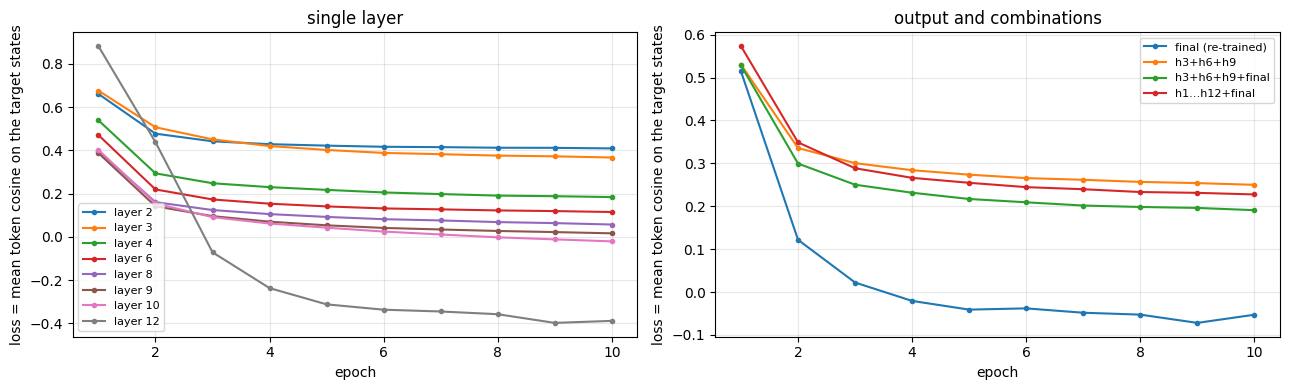

In [6]:
if RERUN:
    for t in TARGETS:
        if not (RES / f"v_{t}.npy").exists():
            train_uap(VIS, B_u8, t)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t in TARGETS:
    h = load(f"train_{t}.json")["history"]
    a = ax[1] if t.startswith("multi") or t == "final" else ax[0]
    a.plot([x["epoch"] for x in h], [x["loss"] for x in h], marker="o", ms=3, label=LABEL[t])
for a, ttl in zip(ax, ["single layer", "output and combinations"]):
    a.set_xlabel("epoch"); a.set_ylabel("loss = mean token cosine on the target states"); a.set_title(ttl); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Task 1: which layer should the loss target? (SmolVLM-256M)

Real pipeline, 200 held-out images with splitting off, 100 with splitting on (the model's default).

In [7]:
if RERUN:
    clean = {False: captions(proc, model, E_u8[:200], None, False), True: captions(proc, model, E_u8[:100], None, True, bs=2)}
    save("clean_256M_off_200.json", clean[False]); save("clean_256M_on_100.json", clean[True])
    for v in ORDER:
        pert, R = load_v(v), {}
        R["caps_off"] = captions(proc, model, E_u8[:200], pert, False); R["off"] = changed_stats(clean[False], R["caps_off"])
        R["caps_on"] = captions(proc, model, E_u8[:100], pert, True, bs=2); R["on"] = changed_stats(clean[True], R["caps_on"])
        R["layers"] = layer_damage(proc, VIS, E_u8[:50], pert)
        save(f"eval_256M_{v}.json", R)

E256 = {v: load(f"eval_256M_{v}.json") for v in ORDER}
print(f"{'loss target':24s}{'off (200)':>11s}{'95% CI':>16s}{'@0.7':>8s}{'on (100)':>10s}{'cos out':>9s}{'cos h6':>8s}")
print("-" * 86)
for v in ORDER:
    r = E256[v]; o = r["off"]; on = r.get("on")
    print(f"{LABEL[v]:24s}{pct(o['changed']):>11s}{pct(o['ci95'][0]) + '-' + pct(o['ci95'][1]):>16s}{pct(o['changed@0.7']):>8s}"
          f"{pct(on['changed']) if on else '-':>10s}{r['layers']['final']:>9.3f}{r['layers']['h6']:>8.3f}")

loss target               off (200)          95% CI    @0.7  on (100)  cos out  cos h6
--------------------------------------------------------------------------------------
random ±ε                      2.5%       1.1%-5.7%   15.0%      4.0%    0.866   0.910
group v (final, nb 01)        71.0%     64.4%-76.8%   83.5%     59.0%    0.142   0.426
final (re-trained)            69.0%     62.3%-75.0%   81.0%     56.0%    0.202   0.468
layer 2                       40.0%     33.5%-46.9%   69.0%         -    0.561   0.494
layer 3                       55.5%     48.6%-62.2%   75.0%     36.0%    0.523   0.372
layer 4                       73.5%     67.0%-79.1%   88.5%         -    0.474   0.263
layer 6                       63.0%     56.1%-69.4%   87.0%     47.0%    0.337   0.191
layer 8                       76.0%     69.6%-81.4%   87.0%         -    0.476   0.318
layer 9                       66.5%     59.7%-72.7%   86.0%     46.0%    0.494   0.345
layer 10                      72.0%     65.

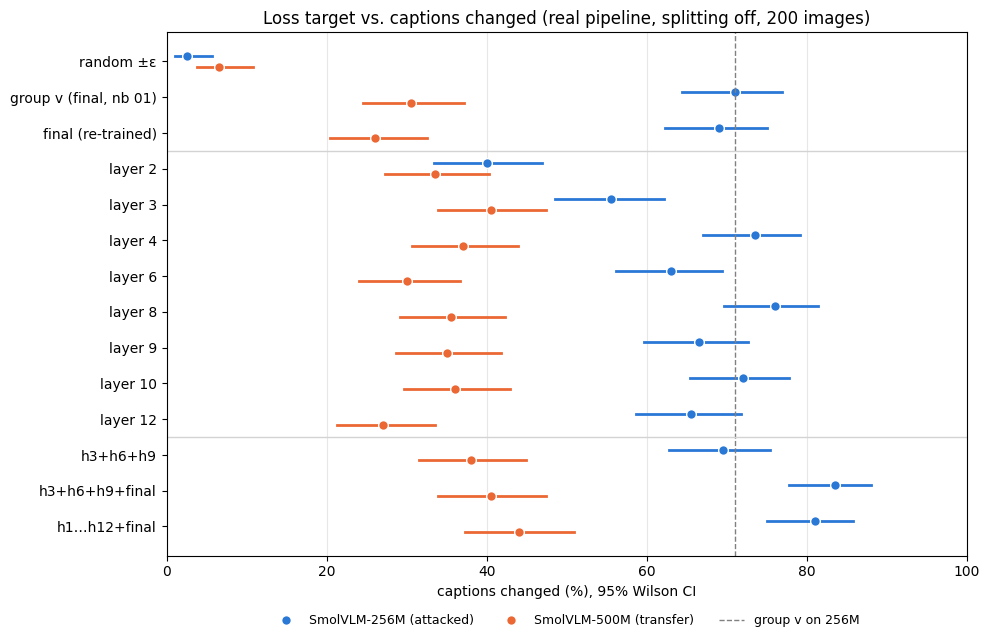

In [8]:
E500 = {v: load(f"eval_500M_{v}.json") for v in ORDER}
fig, ax = plt.subplots(figsize=(10, 6.5))
ys = np.arange(len(ORDER))[::-1]
for (E, col, dy, lab) in [(E256, "#2a78d6", 0.15, "SmolVLM-256M (attacked)"), (E500, "#eb6834", -0.15, "SmolVLM-500M (transfer)")]:
    for y, v in zip(ys, ORDER):
        o = E[v]["off"]
        ax.plot([100 * o["ci95"][0], 100 * o["ci95"][1]], [y + dy] * 2, color=col, lw=2)
        ax.plot(100 * o["changed"], y + dy, "o", color=col, ms=7, mec="white", label=lab if v == "random" else None)
ax.axvline(100 * E256["group_final"]["off"]["changed"], color="gray", ls="--", lw=1, label="group v on 256M")
ax.set_yticks(ys, [LABEL[v] for v in ORDER]); ax.set_xlim(0, 100); ax.set_xlabel("captions changed (%), 95% Wilson CI")
for y in (ys[2] - 0.5, ys[10] - 0.5): ax.axhline(y, color="lightgray", lw=1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=9, frameon=False); ax.grid(axis="x", alpha=.3)
ax.set_title("Loss target vs. captions changed (real pipeline, splitting off, 200 images)")
plt.tight_layout(); plt.show()

**Paired test and the attractor.** Same 200 images for every perturbation, so we can count the images that one perturbation breaks and the other does not (exact McNemar test). We also count the "person in a white shirt" attractor from Section 6 of the report.

In [9]:
CA = load("caption_analysis.json")
for k in ["multi_vs_group_final", "multi_vs_final", "multi_all_vs_group_final"]:
    a, b = k.split("_vs_")
    print(f"{LABEL[a]:16s} vs {LABEL[b]:24s}: only {LABEL[a]} breaks {CA[k]['only_a']:3d} | only {LABEL[b]} breaks {CA[k]['only_b']:2d} | p = {CA[k]['mcnemar_p']:.1e}")
print(f"\n{'perturbation':24s}{'white shirt':>12s}{'person':>9s}{'distinct captions / 200':>26s}")
for v in ["random", "group_final", "final", "h6", "multi", "multi_all"]:
    c = CA[v]; print(f"{LABEL[v]:24s}{pct(c['white_shirt']):>12s}{pct(c['person']):>9s}{c['distinct']:>26d}")

h3+h6+h9+final   vs group v (final, nb 01)  : only h3+h6+h9+final breaks  30 | only group v (final, nb 01) breaks  5 | p = 2.2e-05
h3+h6+h9+final   vs final (re-trained)      : only h3+h6+h9+final breaks  31 | only final (re-trained) breaks  2 | p = 1.3e-07
h1…h12+final     vs group v (final, nb 01)  : only h1…h12+final breaks  25 | only group v (final, nb 01) breaks  5 | p = 3.2e-04

perturbation             white shirt   person   distinct captions / 200
random ±ε                       0.0%    11.0%                       184
group v (final, nb 01)         13.5%    27.0%                       178
final (re-trained)             11.5%    24.5%                       173
layer 6                        30.0%    43.5%                       102
h3+h6+h9+final                 16.0%    30.0%                       167
h1…h12+final                   10.0%    25.0%                       173


## 8. Why the combination wins: it survives the real pipeline

Damage at the encoder output (token cosine, 1 = intact) in the training setting (v added after preprocessing) and through the real pipeline (8-bit file + processor resampling), 50 images.

In [10]:
if RERUN:
    ROB = {}
    with torch.no_grad():
        for v in ORDER:
            pert, acc = load_v(v), {}
            for i in range(0, 50, 10):
                x = to01(E_u8[i:i + 10]); s0, s1 = encoder_states(VIS, norm(x)), encoder_states(VIS, norm((x + pert).clamp(0, 1)))
                for k in s0: acc.setdefault(k, []).append(tok_cos(s0[k], s1[k]).cpu())
            ROB[v] = {"after_preproc": {k: torch.cat(a).mean().item() for k, a in acc.items()}, "real": load(f"eval_256M_{v}.json")["layers"]}
    save("robustness.json", ROB)

ROB = load("robustness.json")
show = [v for v in ["random", "group_final", "final", "h3", "h6", "h9", "multi_mid", "multi", "multi_all"] if v in ROB]
print(f"{'perturbation':24s}{'after preproc':>15s}{'real pipeline':>15s}{'effect lost':>13s}")
for v in show:
    a, r = ROB[v]["after_preproc"]["final"], ROB[v]["real"]["final"]
    print(f"{LABEL[v]:24s}{a:>15.3f}{r:>15.3f}{r - a:>+13.3f}")

perturbation              after preproc  real pipeline  effect lost
random ±ε                         0.846          0.866       +0.020
group v (final, nb 01)           -0.062          0.142       +0.204
final (re-trained)               -0.026          0.202       +0.228
layer 3                           0.489          0.523       +0.034
layer 6                           0.203          0.337       +0.135
layer 9                           0.482          0.494       +0.012
h3+h6+h9                          0.452          0.481       +0.029
h3+h6+h9+final                   -0.059          0.085       +0.144
h1…h12+final                     -0.048          0.104       +0.153


## 9. Task 2: how similar are the 256M and 500M encoders, layer by layer?

Left: the same 50 clean images through both encoders (functional similarity). Right: relative difference of the weight matrices, ‖W_a − W_b‖ / ‖W_a‖ (biases and LayerNorm excluded, see the note below).

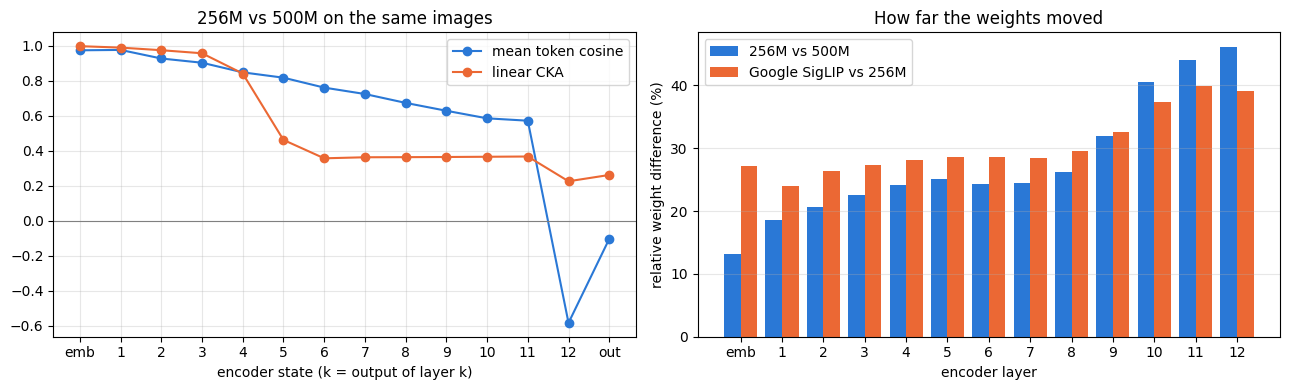

Note: the report's '1.9%' is the median over all 197 tensors; 123 of them are biases / LayerNorm (~1% change).
The 74 weight matrices (99.9% of the parameters) differ by 26% (median) between 256M and 500M.


In [11]:
if RERUN:
    p5, m5 = load_vlm("500M"); VIS5 = m5.model.vision_model
    acc = {}
    with torch.no_grad():
        for i in range(0, 50, 10):
            px = proc.image_processor(images=[[to_pil(u)] for u in E_u8[i:i + 10]], do_image_splitting=False, return_tensors="pt")["pixel_values"].flatten(0, 1).to(DEVICE)
            s1, s2 = encoder_states(VIS, px), encoder_states(VIS5, px)
            for k in s1: acc.setdefault(k, []).append((s1[k].flatten(0, 1)[::4].cpu(), s2[k].flatten(0, 1)[::4].cpu(), tok_cos(s1[k], s2[k]).cpu()))
    def cka(X, Y):
        X, Y = X - X.mean(0), Y - Y.mean(0); return ((Y.T @ X).norm() ** 2 / ((X.T @ X).norm() * (Y.T @ Y).norm())).item()
    save("similarity_256_500.json", {k: {"token_cos": torch.cat([c for _, _, c in a]).mean().item(),
                                         "cka": cka(torch.cat([x for x, _, _ in a]), torch.cat([y for _, y, _ in a]))} for k, a in acc.items()})
    del m5; torch.cuda.empty_cache()

SIM, WD = load("similarity_256_500.json"), load("weight_diff_per_layer.json")
ks = list(SIM); xs = np.arange(len(ks)); names = ["emb" if k == "h0" else "out" if k == "final" else k[1:] for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(xs, [SIM[k]["token_cos"] for k in ks], "o-", color="#2a78d6", label="mean token cosine")
ax[0].plot(xs, [SIM[k]["cka"] for k in ks], "o-", color="#eb6834", label="linear CKA")
ax[0].axhline(0, color="gray", lw=.8); ax[0].set_xticks(xs, names); ax[0].set_xlabel("encoder state (k = output of layer k)")
ax[0].set_title("256M vs 500M on the same images"); ax[0].legend(); ax[0].grid(alpha=.3)
wk = [k for k in WD if k != "note"]
ax[1].bar(np.arange(len(wk)) - .2, [100 * WD[k]["256M_vs_500M"] for k in wk], .4, color="#2a78d6", label="256M vs 500M")
ax[1].bar(np.arange(len(wk)) + .2, [100 * WD[k]["google_vs_256M"] for k in wk], .4, color="#eb6834", label="Google SigLIP vs 256M")
ax[1].set_xticks(np.arange(len(wk)), ["emb" if k == "embeddings" else k.split("_")[1] for k in wk]); ax[1].set_ylabel("relative weight difference (%)")
ax[1].set_xlabel("encoder layer"); ax[1].set_title("How far the weights moved"); ax[1].legend(); ax[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()
print("Note: the report's '1.9%' is the median over all 197 tensors; 123 of them are biases / LayerNorm (~1% change).")
print("The 74 weight matrices (99.9% of the parameters) differ by 26% (median) between 256M and 500M.")

## 10. Transfer table

SmolVLM columns: % of captions changed (200 images; 100 for 2.2B). Google SigLIP (zero-shot ImageNet classification with "a photo of a {class}."), ResNet-50 and ViT-B/16 (torchvision weights): **fooling rate** as in the 2017 paper, i.e. % of the 500 held-out images whose top-1 prediction changes. The perturbed 512 px image goes through each model's own preprocessing.

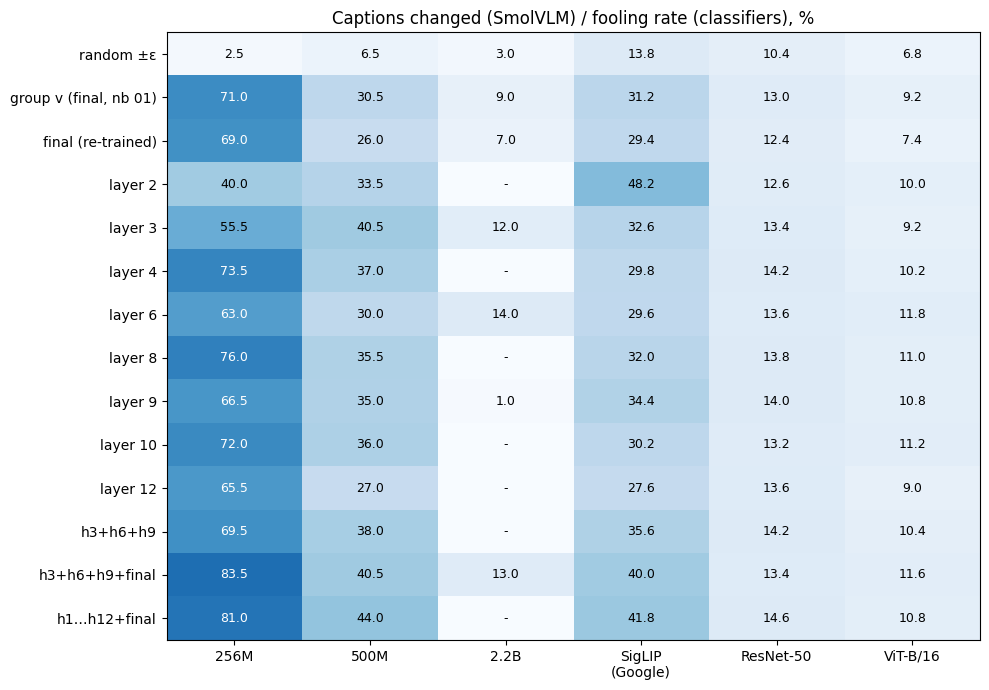

clean accuracy: {'SigLIP (Google)': '67.6%', 'ResNet-50': '69.4%', 'ViT-B/16': '71.4%'}


In [12]:
if RERUN:
    import torchvision
    from transformers import AutoModel
    syn = Path("synset_words.txt")                                                   # ImageNet class names (repo copy)
    if not syn.exists():
        os.system("wget -q -O synset_words.txt https://raw.githubusercontent.com/raathi75/EA_universal_perturbation/main/Experiments%20ViT/python/data/synset_words.txt")
    names = [l.split(" ", 1)[1].split(",")[0].strip() for l in open(syn)]
    sp = AutoProcessor.from_pretrained("google/siglip-base-patch16-512")
    sm = AutoModel.from_pretrained("google/siglip-base-patch16-512").to(DEVICE).eval()
    with torch.no_grad():
        tin = sp(text=[f"a photo of a {n}." for n in names], padding="max_length", max_length=64, return_tensors="pt").to(DEVICE)
        tf_ = lambda ids: (lambda o: o if torch.is_tensor(o) else o.pooler_output)(sm.get_text_features(input_ids=ids))
        T = F.normalize(torch.cat([tf_(tin["input_ids"][i:i + 100]) for i in range(0, 1000, 100)]), dim=-1)
    W = torchvision.models
    CLS = {"ResNet-50": (W.resnet50(weights="IMAGENET1K_V2").to(DEVICE).eval(), W.ResNet50_Weights.IMAGENET1K_V2.transforms()),
           "ViT-B/16": (W.vit_b_16(weights="IMAGENET1K_V1").to(DEVICE).eval(), W.ViT_B_16_Weights.IMAGENET1K_V1.transforms())}
    @torch.no_grad()
    def predict(pert):
        P = {"SigLIP (Google)": [], **{k: [] for k in CLS}}
        for i in range(0, N_EVAL, 25):
            pils = [to_pil(u, pert) for u in E_u8[i:i + 25]]
            f = F.normalize(sm.vision_model(pixel_values=sp(images=pils, return_tensors="pt")["pixel_values"].to(DEVICE)).pooler_output, dim=-1)
            P["SigLIP (Google)"].append((f @ T.T).argmax(-1).cpu())
            for k, (m, tf) in CLS.items(): P[k].append(m(torch.stack([tf(p) for p in pils]).to(DEVICE)).argmax(-1).cpu())
        return {k: torch.cat(v) for k, v in P.items()}
    y, clean = torch.tensor(Y_eval), predict(None)
    TR = {"clean": {k: {"acc": (p == y).float().mean().item()} for k, p in clean.items()}}
    for v in ORDER:
        pr = predict(load_v(v))
        TR[v] = {k: {"fooling_rate": (p != clean[k]).float().mean().item(), "ci95": wilson(int((p != clean[k]).sum()), N_EVAL),
                     "acc": (p == y).float().mean().item()} for k, p in pr.items()}
    save("transfer_other.json", TR)
    for key in ["500M", "2.2B"]:
        p5, m5 = load_vlm(key); n = 200 if key == "500M" else 100
        c0 = captions(p5, m5, E_u8[:n], None, False, bs=8 if key == "500M" else 2)
        for v in ORDER:
            c1 = captions(p5, m5, E_u8[:n], load_v(v), False, bs=8 if key == "500M" else 2)
            save(f"eval_{key}_{v}.json", {"off": changed_stats(c0, c1), "caps_off": c1})
        del m5; torch.cuda.empty_cache()

TR = load("transfer_other.json")
cols = ["256M", "500M", "2.2B", "SigLIP (Google)", "ResNet-50", "ViT-B/16"]
M = np.full((len(ORDER), len(cols)), np.nan)
for i, v in enumerate(ORDER):
    for j, c in enumerate(cols):
        if c in ("256M", "500M", "2.2B"):
            e = load(f"eval_{c}_{v}.json"); M[i, j] = e["off"]["changed"] if e else np.nan
        elif v in TR:
            M[i, j] = TR[v][c]["fooling_rate"]
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(np.nan_to_num(M, nan=0), cmap="Blues", vmin=0, vmax=1.1, aspect="auto")
for i in range(len(ORDER)):
    for j in range(len(cols)):
        ax.text(j, i, "-" if np.isnan(M[i, j]) else f"{100 * M[i, j]:.1f}", ha="center", va="center", fontsize=9,
                color="white" if M[i, j] > 0.6 else "black")
ax.set_xticks(range(len(cols)), [c.replace(" (Google)", "\n(Google)") for c in cols]); ax.set_yticks(range(len(ORDER)), [LABEL[v] for v in ORDER])
ax.set_title("Captions changed (SmolVLM) / fooling rate (classifiers), %"); plt.tight_layout(); plt.show()
print("clean accuracy:", {k: pct(x["acc"]) for k, x in TR["clean"].items()})

## 11. Summary

**Task 1: middle layers.**
- A single middle layer does **not** beat the output: layers 2–3 alone are clearly weaker (40%, 55.5%), and layers 4–12 alone stay within the output's confidence interval (63–76% vs 69–71%).
- **Combining the output with middle layers gains about 12 points**: h3+h6+h9+final changes 83.5% of captions (CI 77.7–88.0) vs 71.0% for the group's v. Paired test: 30 images broken only by the combination vs 5 only by the group's v (p < 10⁻⁴). The gain holds with splitting on (72% vs 59%, 100 images). Without the output term (h3+h6+h9) it drops back to 69.5%, so both parts are needed.
- **Why**: the combined perturbation keeps more of its effect through the real pipeline (output token cosine loses 0.14 instead of 0.20–0.23 when going through the 8-bit file and resampling).
- Targeting layer 6 alone gives a much stronger attractor: 30% "white shirt" captions and only 102 distinct captions out of 200 (VLM analogue of the 2017 dominant labels).

**Task 2: transfer.**
- 256M and 500M encoders are nearly identical in layers 1–3 (token cosine ≥ 0.90, CKA ≥ 0.96) and diverge with depth (output cosine −0.10). Their weight matrices differ by 26% (median), not 1.9%.
- **To 500M**, combinations transfer best (h1…h12+final 44.0%, h3+h6+h9+final 40.5%, layer 3 alone 40.5%) vs 30.5% for the group's v.
- **To the original Google SigLIP**, the lowest layer (layer 2) transfers best (48%) vs 31% for the group's v and 14% for random noise.
- **No real transfer** to SmolVLM-2.2B (≤ 14% vs 3%), ResNet-50 or ViT-B/16 (1–5 points above random noise), mirroring the report's GoogLeNet → SmolVLM result.

**Limits.** One seed per perturbation; layers 3/6/9 for the combination were chosen a priori, not tuned; splitting on and 2.2B on 100 images only; the defenses of notebooks 05–07 were not re-run with the new perturbation.